# $\log 2$: historical constructions

Each section constructs a CMF, walks a trajectory with ramanujantools and prints $\delta_N$ at the deepest sample, where $|\log 2-p_N/q_N|=q_N^{-(1+\delta_N)}$ for the reduced $p_N/q_N$. Run the cells in order with `cmfs.py` next to this notebook. A finite-depth $\delta_N$ does not prove a measure bound.

In [1]:
# @title Install dependencies (run once per environment)
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 mpmath==1.3.0 matplotlib==3.11.2

## Setup

$(s_0,s_1,\ldots)$ is the first column of the walk.

In [2]:
import sys

import matplotlib.pyplot as plt
import sympy as sp
from flint import arb, ctx
from ramanujantools import Matrix
from ramanujantools.cmf.pfq import pFq

from cmfs import rhin_log2

sys.set_int_max_str_digits(0)
with ctx.workdps(62_000):  # q_N reaches about 28,000 digits at depth 3000
    LOG2 = arb(2).log()
DEPTHS = list(range(10, 3001, 10))
x0, x1, x2, y0, y1 = sp.symbols("x0 x1 x2 y0 y1")
results = {}


def delta(approximant):
    """delta with |log 2 - p/q| = q^-(1 + delta), for the reduced fraction p/q."""
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(2 * q.bit_length() + 64):  # enough bits to resolve |log 2 - p/q|
        error = abs(LOG2 - arb(p) / q)
    return float((-1 - error.log() / arb(q).log()).mid())

## 1. Alladi–Robinson (1980)

J. Reine Angew. Math. **318** (1980); see [Zudilin (2004), §1](https://arxiv.org/html/math/0404523) · $\mu(\log 2)\le4.6221$

${}_2F_1(-1)$ · start $(1,1;2)$ · trajectory $(1,1;2)$ · $p_N/q_N=s_1/[2(s_1-s_0)]$

In [3]:
cmf = pFq(2, 1, -1)
start = {x0: 1, x1: 1, y0: 2}
trajectory = {x0: 1, x1: 1, y0: 2}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [W[1, 0] / (2 * (W[1, 0] - W[0, 0])) for W in walks]
deltas = [delta(r) for r in approximants]
results["Alladi–Robinson (1980)"] = (DEPTHS, deltas)
print(f"delta at depth 3000: {deltas[-1]:.9f}")

delta at depth 3000: 0.282414787


## 2. Rukhadze (1987)

$\mu(\log 2)<3.89139978$

${}_2F_1(-1)$, dual · start $(1,1;2)$ · trajectory $(7,6;14)$ · $p_N/q_N=s_0/(2s_1+2s_0)$

In [4]:
cmf = pFq(2, 1, -1).dual()  # inverse-transpose matrices
start = {x0: 1, x1: 1, y0: 2}
trajectory = {x0: 7, x1: 6, y0: 14}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [W[0, 0] / (2 * W[1, 0] + 2 * W[0, 0]) for W in walks]
deltas = [delta(r) for r in approximants]
results["Rukhadze (1987)"] = (DEPTHS, deltas)
print(f"delta at depth 3000: {deltas[-1]:.9f}")

delta at depth 3000: 0.346072067


## 3. Marcovecchio (2009)

[Acta Arith. **139** (2009)](https://doi.org/10.4064/aa139-2-5) · $\mu(\log 2)<3.57455391$

${}_3F_2(\tfrac12)$ · start $(1,1,1;2,1)$ · trajectory $(7,5,6;2,1)$ · $p_N/q_N=(s_1-s_0)/s_1$

In [5]:
cmf = pFq(3, 2, sp.Rational(1, 2))
start = {x0: 1, x1: 1, x2: 1, y0: 2, y1: 1}
trajectory = {x0: 7, x1: 5, x2: 6, y0: 2, y1: 1}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(W[1, 0] - W[0, 0]) / W[1, 0] for W in walks]
deltas = [delta(r) for r in approximants]
results["Marcovecchio (2009)"] = (DEPTHS, deltas)
print(f"delta at depth 3000: {deltas[-1]:.9f}")

delta at depth 3000: 0.388170433


## 4. Chudnovsky benchmark (Rhin's reconstruction)

[Rhin (1987), pp. 159–160](https://doi.org/10.1007/978-1-4757-4267-1_11) · $\mu(\log 2)\le4.1344$; Rhin calls the attribution to Chudnovsky probable

Moment CMF of $\int_0^1t^j\,(t(1-t))^{e_1}(6t^2-5t+1)^{e_2}(1+t)^{-b}\,dt$ (`rhin_log2`) · start $(0,0,1)$ · trajectory $(9,1,10)$, so depth $k$ is $N=10k$ · $S_j=C_j+R_j\log 2$, $p_N/q_N=-C_0/R_0$

In [6]:
e1, e2, b = sp.symbols("e1 e2 b")
cmf = rhin_log2()
start = {e1: 0, e2: 0, b: 1}
trajectory = {e1: 9, e2: 1, b: 10}
walks = cmf.walk(trajectory, [N // 10 for N in DEPTHS], start)  # depth k is N = 10k
# S_j = C_j + R_j log 2 at the start.
C = Matrix([[0, 1, -sp.Rational(1, 2), sp.Rational(5, 6)]])
R = Matrix([[1, -1, 1, -1]])
approximants = [-(C * W)[0] / (R * W)[0] for W in walks]
deltas = [delta(r) for r in approximants]
results["Chudnovsky benchmark (Rhin reconstruction)"] = (DEPTHS, deltas)
print(f"delta at N = 3000: {deltas[-1]:.9f}")

delta at N = 3000: 0.323450419


## All constructions

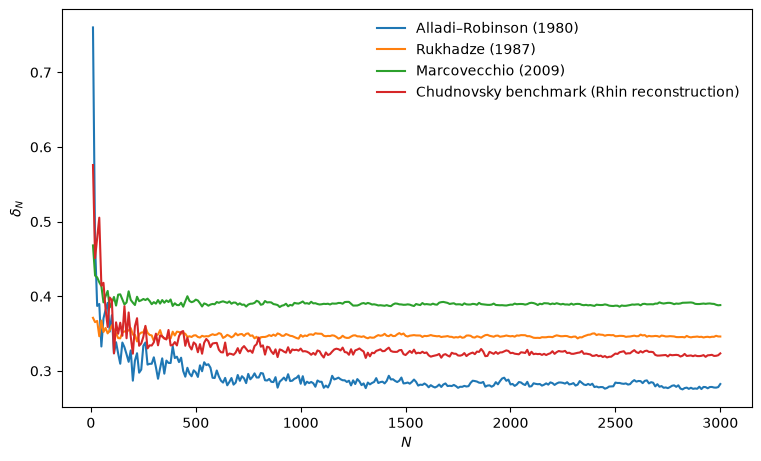

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4.5), constrained_layout=True)
for name, (depths, values) in results.items():
    ax.plot(depths, values, label=name)
ax.set(xlabel="$N$", ylabel=r"$\delta_N$")
ax.legend(frameon=False)
plt.show()

## Historical overview

| Construction | Published bound | Here |
|:--|--:|:--|
| Alladi–Robinson (1980) | $4.6221$ | CMF |
| Chudnovsky (1980s) | $4.1344$ | CMF of Rhin's reconstruction |
| Rukhadze (1987) | $3.89139978$ | CMF |
| Marcovecchio (2009) | $3.57455391$ | CMF |

Earlier records: [Rhin–Viola (1993), introduction](https://www.numdam.org/item/AIF_1993__43_1_85_0/).